# Soluciones a las tareas planteadas de la práctica 3

Antes que nada, ejecutar esta primera celda para importar todas las librerías necesarias.

In [4]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv
from collections import deque

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
from sklearn.model_selection import GroupKFold, cross_val_predict

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



C:\Users\paula\AppData\Local\Temp\ipykernel_21572\1081712699.py:41: RuntimeWarning: overflow encountered in scalar subtract
  distancias = [np.sqrt((x - cx)**2 + (y - cy)**2) for (cx, cy, _) in circles[0, :]]
C:\Users\paula\AppData\Local\Temp\ipykernel_21572\1081712699.py:41: RuntimeWarning: overflow encountered in scalar add
  distancias = [np.sqrt((x - cx)**2 + (y - cy)**2) for (cx, cy, _) in circles[0, :]]


Moneda de referencia seleccionada en (136, 346), radio 92px


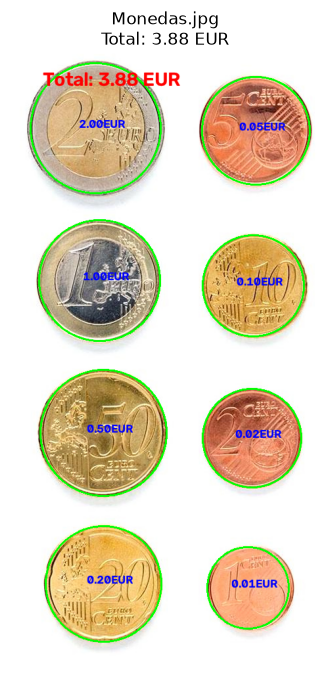

In [2]:
# cargar imagen de monedas
img = cv2.imread("Monedas.jpg")
if img is None:
    raise IOError("No se pudo cargar Monedas.jpg")

def redimensionar_imagen(img, ancho_max=800):
    alto, ancho = img.shape[:2]
    if ancho > ancho_max:
        escala = ancho_max / ancho
        nuevo_ancho = int(ancho * escala)
        nuevo_alto = int(alto * escala)
        img_redim = cv2.resize(img, (nuevo_ancho, nuevo_alto))
        return img_redim
    else:
        return img

def procesar_monedas(img):
    img_display = img.copy()
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 5)

    circles = cv2.HoughCircles(
        gray, cv2.HOUGH_GRADIENT, dp=1, minDist=50,
        param1=100, param2=45, minRadius=25, maxRadius=100
    )
    if circles is None:
        raise ValueError("No se detectaron monedas en la imagen.")
    circles = np.uint16(np.around(circles))

    for (x, y, r) in circles[0, :]:
        cv2.circle(img_display, (x, y), r, (0, 255, 0), 2)
        cv2.circle(img_display, (x, y), 2, (0, 0, 255), 3)

    ref_diametro_mm = 23.25
    escala_mm_px = None
    ref_pos = None

    def seleccionar_moneda(event, x, y, flags, param):
        nonlocal escala_mm_px, ref_pos, img_display
        if event == cv2.EVENT_LBUTTONDOWN:
            distancias = [np.sqrt((x - cx)**2 + (y - cy)**2) for (cx, cy, _) in circles[0, :]]
            idx = np.argmin(distancias)
            (cx, cy, r) = circles[0][idx]
            ref_pos = (cx, cy)
            diametro_ref_px = 2 * r
            escala_mm_px = ref_diametro_mm / diametro_ref_px
            print(f"Moneda de referencia seleccionada en ({cx}, {cy}), radio {r}px")
            img_display[:] = img.copy()
            for (x0, y0, r0) in circles[0, :]:
                cv2.circle(img_display, (x0, y0), r0, (0, 255, 0), 2)
            cv2.circle(img_display, (cx, cy), r, (0, 0, 255), 3)

    cv2.namedWindow("Selecciona moneda de referencia")
    cv2.setMouseCallback("Selecciona moneda de referencia", seleccionar_moneda)
    while escala_mm_px is None:
        cv2.imshow("Selecciona moneda de referencia", img_display)
        if cv2.waitKey(1) & 0xFF == 27:
            break
    cv2.destroyAllWindows()

    if escala_mm_px is None:
        raise ValueError("No se seleccionó ninguna moneda de referencia.")

    monedas_info = {
        16.25: 0.01, 18.75: 0.02, 19.75: 0.10, 21.25: 0.05,
        22.25: 0.20, 23.25: 1.00, 24.25: 0.50, 25.75: 2.00
    }

    total = 0
    resultado = img.copy()
    for (x, y, r) in circles[0, :]:
        diametro_mm = 2 * r * escala_mm_px
        diametro_real = min(monedas_info.keys(), key=lambda d: abs(d - diametro_mm))
        valor = monedas_info[diametro_real]
        total += valor
        cv2.circle(resultado, (x, y), r, (0, 255, 0), 2)
        cv2.putText(resultado, f"{valor:.2f}EUR", (x - 25, y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    cv2.putText(resultado, f"Total: {total:.2f} EUR", (50, 50),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 3)

    return resultado, total


resultado1, total1 = procesar_monedas(img)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(resultado1, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"Monedas.jpg\nTotal: {total1:.2f} EUR")
plt.show()

In [3]:
monedas_info = {
    16.25: 0.01, 18.75: 0.02, 19.75: 0.10, 21.25: 0.05,
    22.25: 0.20, 23.25: 1.00, 24.25: 0.50, 25.75: 2.00
}

def detectar_monedas(frame):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 5)
    circles = cv2.HoughCircles(
        gray, cv2.HOUGH_GRADIENT, dp=1, minDist=50,
        param1=100, param2=45, minRadius=25, maxRadius=100
    )
    if circles is None:
        return None
    return np.uint16(np.around(circles))[0, :]

N_HISTORIAL = 15  # fotogramas que se promedian por moneda; sube el numero si sigue parpadeando

def actualiza_tracks(circles, tracks, siguiente_id, max_dist=40):
    """Empareja cada circulo detectado ahora con el track mas cercano del fotograma
    anterior (misma moneda siguiendose en el tiempo) y acumula su historial de radios."""
    nuevos_tracks = {}
    usados = set()
    if circles is None:
        return nuevos_tracks, siguiente_id
    for (x, y, r) in circles:
        mejor_id, mejor_dist = None, max_dist
        for tid, info in tracks.items():
            if tid in usados:
                continue
            cx, cy = info["pos"]
            d = np.hypot(int(x) - cx, int(y) - cy)
            if d < mejor_dist:
                mejor_dist, mejor_id = d, tid
        if mejor_id is None:
            mejor_id = siguiente_id
            siguiente_id += 1
            historial = deque(maxlen=N_HISTORIAL)
        else:
            usados.add(mejor_id)
            historial = tracks[mejor_id]["radios"]
        historial.append(int(r))
        nuevos_tracks[mejor_id] = {"pos": (int(x), int(y)), "radios": historial}
    return nuevos_tracks, siguiente_id

ref_diametro_mm = 23.25   # moneda de referencia: 1 euro
escala_mm_px = None

def seleccionar_moneda(event, x, y, flags, circles):
    global escala_mm_px
    if event == cv2.EVENT_LBUTTONDOWN and circles is not None and len(circles) > 0:
        distancias = [np.sqrt((x - cx) ** 2 + (y - cy) ** 2) for (cx, cy, r) in circles]
        idx = np.argmin(distancias)
        cx, cy, r = circles[idx]
        escala_mm_px = ref_diametro_mm / (2 * r)
        print(f"Calibrado con moneda en ({cx},{cy}), radio {r}px -> {escala_mm_px:.4f} mm/px")

cap = cv2.VideoCapture("http://192.168.1.14:8080/video") # IP del móvil con IP Webcam
cv2.namedWindow("Dinero en vivo")
print("Haz clic sobre la moneda de 1 euro para calibrar (puedes repetirlo). ESC para salir.")

tracks = {}
siguiente_id = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    circles = detectar_monedas(frame)
    cv2.setMouseCallback("Dinero en vivo", seleccionar_moneda, circles)

    tracks, siguiente_id = actualiza_tracks(circles, tracks, siguiente_id)

    display = frame.copy()
    total = 0
    for tid, info in tracks.items():
        x, y = info["pos"]
        # solo clasifica monedas con historial suficiente, para no fiarse de 1-2 fotogramas
        if len(info["radios"]) < 5:
            cv2.circle(display, (x, y), int(np.median(info["radios"])), (0, 200, 200), 2)
            continue
        r_suave = np.median(info["radios"])
        cv2.circle(display, (x, y), int(r_suave), (0, 255, 0), 2)

        if escala_mm_px is not None:
            diametro_mm = 2 * r_suave * escala_mm_px
            diametro_real = min(monedas_info.keys(), key=lambda d: abs(d - diametro_mm))
            valor = monedas_info[diametro_real]
            total += valor
            cv2.putText(display, f"{valor:.2f}", (x - 20, y),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

    if escala_mm_px is not None:
        cv2.putText(display, f"Total: {total:.2f} EUR", (20, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)
    else:
        cv2.putText(display, "Haz clic sobre la moneda de 1 euro para calibrar",
                    (20, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

    cv2.imshow("Dinero en vivo", display)
    if cv2.waitKey(20) & 0xFF == 27:   # ESC
        break

cap.release()
cv2.destroyAllWindows()

Haz clic sobre la moneda de 1 euro para calibrar (puedes repetirlo). ESC para salir.


TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje `profunfop ni poara segmentar,  ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

PEL pellet-03-olympus-10-01-2020.JPG: 56 partículas (imagen original)
PEL PEL.png: 11 partículas (imagen original)
TAR tar-03-olympus-10-01-2020.JPG: 52 partículas (imagen original)
TAR TAR.png: 9 partículas (imagen original)
FRA fragment-03-olympus-10-01-2020.JPG: 75 partículas (imagen original)
FRA FRA.png: 15 partículas (imagen original)

Muestras de entrenamiento (con aumentación): 3762

=== Validación cruzada (train, agrupada por partícula) ===
              precision    recall  f1-score   support

         PEL       0.89      0.82      0.85      1182
         TAR       0.86      0.93      0.89      1086
         FRA       0.90      0.90      0.90      1494

    accuracy                           0.88      3762
   macro avg       0.88      0.88      0.88      3762
weighted avg       0.88      0.88      0.88      3762


112 partículas de test emparejadas; 8 bboxes sin contorno (no evaluadas)
              precision    recall  f1-score   support

         PEL       0.89      0.69   

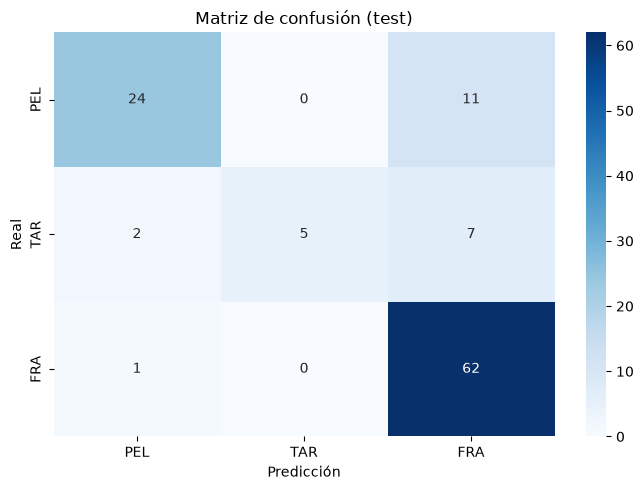

In [7]:
# Cada clase puede tener varias imágenes de entrenamiento.
TRAIN = {
    'PEL': ['pellet-03-olympus-10-01-2020.JPG'],
    'TAR': ['tar-03-olympus-10-01-2020.JPG'],
    'FRA': ['fragment-03-olympus-10-01-2020.JPG'],
}

TRAIN['PEL'].append('PEL.png')
TRAIN['TAR'].append('TAR.png')
TRAIN['FRA'].append('FRA.png')

CLASSES = ['PEL', 'TAR', 'FRA']
CONTRASTS = [1.0, 0.8, 0.6]              # aumentación de contraste (1 = original)
# (k giros de 90º, espejo). solo múltiplos de 90º para no crear bordes artificiales como pasaría con rotaciones arbitrarias.
GEOMS = [(0, False), (1, False), (2, False), (3, False), (0, True), (1, True)]
WIDTH = 1170                              # ancho común al que se reescala todo
MIN_AREA_TRAIN, MIN_AREA_TEST = 20, 10

# NORMALIZACIÓN
def normalize(img, width=WIDTH):
    # reescala a un ancho común. devuelve imagen y factor de escala
    s = width / img.shape[1]
    if abs(s - 1) < 1e-6:
        return img, 1.0
    return cv2.resize(img, (width, int(round(img.shape[0] * s))), interpolation=cv2.INTER_AREA), s

# SEGMENTACIÓN
def background(lab):
    return np.stack([cv2.medianBlur(lab[:, :, i], 101) for i in range(3)], -1).astype(np.float32)

def segment(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    d = np.sqrt(((lab.astype(np.float32) - background(lab)) ** 2).sum(-1))
    d8 = np.clip(cv2.GaussianBlur(d, (5, 5), 0) * 10, 0, 255).astype(np.uint8)
    _, m = cv2.threshold(d8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))

# CARACTERÍSTICAS
def particles(img, min_area):
    # Devuelve [(centroide_x, centroide_y, area, vector_características)]
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB); hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    bg = background(lab); out = []
    cnts, _ = cv2.findContours(segment(img), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in cnts:
        a = cv2.contourArea(c)
        M = cv2.moments(c)
        if a < min_area or M['m00'] == 0:
            continue
        p = cv2.arcLength(c, True); x, y, w, h = cv2.boundingRect(c)
        ell = 0
        if len(c) >= 5:
            _, ax, _ = cv2.fitEllipse(c); ell = min(ax) / max(ax) if max(ax) > 0 else 0
        cx, cy = M['m10'] / M['m00'], M['m01'] / M['m00']
        dist = np.hypot(c[:, 0, 0] - cx, c[:, 0, 1] - cy)
        mask = np.zeros(img.shape[:2], np.uint8); cv2.drawContours(mask, [c], -1, 255, -1)
        mean = np.array(cv2.mean(lab, mask)[:3]); b = np.array([bg[..., i][mask > 0].mean() for i in range(3)])
        dA, dB = (mean - b)[1:]
        hull = max(cv2.contourArea(cv2.convexHull(c)), 1)
        f = [np.sqrt(a),               # tamaño (√área, px a resolución normalizada)
             p,                        # perímetro (px a resolución normalizada)
             p ** 2 / a,               # compacidad (SMACC)
             a / (w * h),              # área / área del contenedor (SMACC)
             min(w, h) / max(w, h),    # ancho/alto del contenedor, simétrico (invariante a giros 90º)
             ell,                      # relación de ejes de la elipse (SMACC)
             dist.min() / dist.max(),  # distancias centroide-contorno (SMACC)
             a / hull,                 # solidez del casco convexo
             4 * np.pi * a / p ** 2,   # circularidad
             mean[0] / max(b[0], 1),   # luminosidad relativa al fondo
             dA, dB, np.hypot(dA, dB), # color relativo al fondo
             cv2.mean(hsv, mask)[1] / 255]
        out.append((cx, cy, a, f))
    return out

# AUMENTAR
def pale(img, k):
    return np.clip(255 - (255 - img.astype(np.float32)) * k, 0, 255).astype(np.uint8)

def transform(img, k, flip):
    out = np.rot90(img, k)
    if flip:
        out = out[:, ::-1]
    return np.ascontiguousarray(out)

def inverse_point(x, y, shape, k, flip):
    # Lleva un punto de la imagen transformada a coordenadas de la imagen original
    Hc, Wc = shape[:2]
    if flip:
        x = Wc - 1 - x
    for _ in range(k):                 # deshacer cada giro de 90º (antihorario)
        x, y = Hc - 1 - y, x
        Hc, Wc = Wc, Hc
    return x, y

# ENTRENAMIENTO
X, y, groups = [], [], []
for label in CLASSES:
    for path in TRAIN[label]:
        im, _ = normalize(cv2.imread(path))
        base = particles(im, MIN_AREA_TRAIN)            # partículas de referencia (para agrupar)
        base_xy = np.array([(cx, cy) for cx, cy, *_ in base])
        print(f'{label} {path}: {len(base)} partículas (imagen original)')
        for k in CONTRASTS:
            for rot, flip in GEOMS:
                var = transform(im if k == 1 else pale(im, k), rot, flip)
                for cx, cy, a, f in particles(var, MIN_AREA_TRAIN):
                    ox, oy = inverse_point(cx, cy, var.shape, rot, flip)
                    d = np.hypot(base_xy[:, 0] - ox, base_xy[:, 1] - oy)
                    j = int(d.argmin())
                    if d[j] > 25:                       # no corresponde a ninguna partícula base
                        continue
                    X.append(f); y.append(label)
                    groups.append(f'{label}|{path}|{j}')  # todas las variantes de una partícula, juntas
X, y, groups = np.array(X), np.array(y), np.array(groups)
print(f'\nMuestras de entrenamiento (con aumentación): {len(X)}')

def new_model():
    return RandomForestClassifier(n_estimators=400, random_state=42,
                                  class_weight='balanced', min_samples_leaf=2, n_jobs=-1)

# validación cruzada SIN tocar el test
cv_pred = cross_val_predict(new_model(), X, y, groups=groups, cv=GroupKFold(n_splits=5))
print('\n=== Validación cruzada (train, agrupada por partícula) ===')
print(classification_report(y, cv_pred, labels=CLASSES, zero_division=0))

model = new_model().fit(X, y)

# TEST
img, s = normalize(cv2.imread('MPs_test.jpg'))
ann = pd.read_csv('MPs_test_bbs.csv')
for col in ['x_min', 'x_max', 'y_min', 'y_max']:
    ann[col] = ann[col] * s                              # las cajas se reescalan igual que la imagen
tp = particles(img, MIN_AREA_TEST)
Xt, yt, miss = [], [], 0
for _, r in ann.iterrows():
    ins = [i for i, (cx, cy, a, _) in enumerate(tp)
           if r.x_min <= cx <= r.x_max and r.y_min <= cy <= r.y_max]
    if not ins:
        miss += 1; continue
    Xt.append(tp[max(ins, key=lambda i: tp[i][2])][3]); yt.append(r.label)
print(f'\n{len(Xt)} partículas de test emparejadas; {miss} bboxes sin contorno (no evaluadas)')
yp = model.predict(np.array(Xt))
print(classification_report(yt, yp, labels=CLASSES, zero_division=0))

cm = confusion_matrix(yt, yp, labels=CLASSES)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Matriz de confusión (test)'); plt.xlabel('Predicción'); plt.ylabel('Real'); plt.tight_layout()
plt.savefig('confusion_matrix_generada.png', dpi=150)